# Lab Assignment-9 — Cognitive Computing (UCS420)
**Name:** Waris  **Roll No.:** 1024170155

1. Cognitive Assistant for reading medicine bottle labels
2. Emotion-aware Cognitive Assistant using facial expression detection

In [ ]:
import os, re, cv2
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from PIL import Image, ImageDraw, ImageFont

# pytesseract.pytesseract.tesseract_cmd = 
%matplotlib inline

# Task 1: Medicine Label Reader

In [2]:
# Dataset: put your downloaded label images in 'medicine_labels'.
# If the folder is empty, 4 sample labels are generated.
DIR = "medicine_labels"
os.makedirs(DIR, exist_ok=True)

if not os.listdir(DIR):
    samples = [
        ("PARACETAMOL TABLETS", "Strength: 500 mg", "EXP 08/2027", "Take 1 tablet twice daily after meals"),
        ("AMOXICILLIN CAPSULES", "Strength: 250 mg", "EXP 12/2026", "Take 1 capsule three times daily"),
        ("IBUPROFEN SYRUP", "Strength: 100 ml", "EXP 05/2028", "Take 5 ml every 6 hours as needed"),
        ("CETIRIZINE TABLETS", "Strength: 10 mg", "EXP 03/2027", "Take 1 tablet daily at night"),
    ]
    try:
        font = ImageFont.truetype("/System/Library/Fonts/Helvetica.ttc", 40)
    except Exception:
        font = ImageFont.load_default(40)
    for i, lines in enumerate(samples, 1):
        img = Image.new("RGB", (900, 450), "white")
        d = ImageDraw.Draw(img)
        for j, t in enumerate(lines):
            d.text((40, 40 + j * 100), t, fill="black", font=font)
        img.save(f"{DIR}/medicine_{i}.png")

files = sorted(f for f in os.listdir(DIR) if f.lower().endswith((".jpg", ".jpeg", ".png")))
print(files)

['medicine_1.png', 'medicine_2.png', 'medicine_3.png', 'medicine_4.png', 'medicine_5.png', 'medicine_6.png']


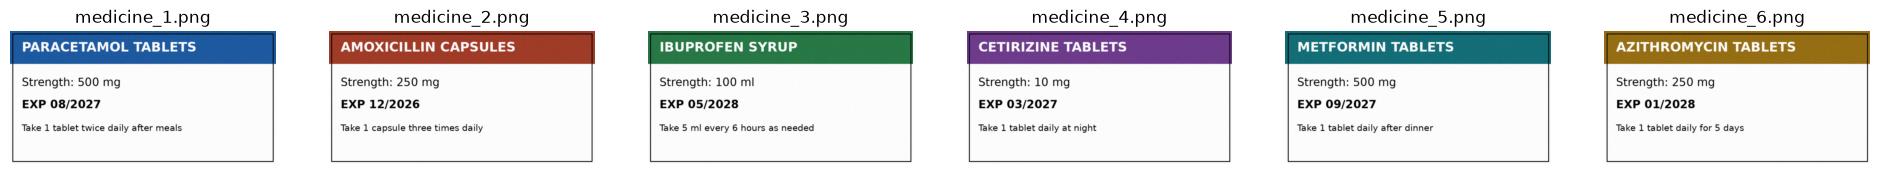

,File,Medicine,Dosage,Expiry,Usage
0,medicine_1.png,PARACETAMOL TABLETS,500 mg,08/2027,Take 1 tablet twice daily after meals
1,medicine_2.png,AMOXICILLIN CAPSULES,250 mg,12/2026,Take 1 capsule three times daily
2,medicine_3.png,IBUPROFEN SYRUP,"100 ml, 5 ml",05/2028,Take 5 ml every 6 hours as needed
3,medicine_4.png,CETIRIZINE TABLETS,10 mg,03/2027,Take 1 tablet daily at night
4,medicine_5.png,METFORMIN TABLETS,500 mg,09/2027,Take 1 tablet daily after dinner
5,medicine_6.png,AZITHROMYCIN TABLETS,250 mg,01/2028,Take 1 tablet daily for 5 days


In [3]:
def read_label(path):
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    _, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)   # preprocessing
    text = pytesseract.image_to_string(bw, config="--psm 6")                    # OCR
    return img, text

def parse(text):
    flat = " ".join(text.split())
    dose   = re.findall(r"\d+\s?(?:mg|mcg|g|ml)\b", flat, re.I)
    expiry = re.findall(r"exp\w*\.?:?\s*(\d{1,2}[/-]\d{2,4})", flat, re.I)
    usage  = re.findall(r"take[^.]*", flat, re.I)
    name   = next((l.strip() for l in text.splitlines() if len(l.strip()) > 3), "")
    return {"Medicine": name,
            "Dosage": ", ".join(dose) or "Not found",
            "Expiry": ", ".join(expiry) or "Not found",
            "Usage": usage[0] if usage else "Not found"}

rows = []
fig, axes = plt.subplots(1, len(files), figsize=(4 * len(files), 3))
axes = axes if len(files) > 1 else [axes]
for ax, f in zip(axes, files):
    img, text = read_label(f"{DIR}/{f}")
    rows.append({"File": f, **parse(text)})
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(f); ax.axis("off")
plt.show()

pd.set_option("display.max_colwidth", 60)
pd.DataFrame(rows)

# Task 2: Emotion-aware Assistant

In [4]:
import glob
from deepface import DeepFace
files = sorted(glob.glob("**/test/happy/*.jpg", recursive=True) + glob.glob("test/happy/*.jpg"))
print(len(files), "happy images found")
for p in files[:60]:
    img = cv2.resize(cv2.imread(p), (224, 224), interpolation=cv2.INTER_CUBIC)
    cv2.imwrite("tmp.jpg", img)
    r = DeepFace.analyze("tmp.jpg", actions=["emotion"], enforce_detection=False)[0]
    if r["dominant_emotion"] == "happy" and r["emotion"]["happy"] > 70:
        cv2.imwrite("face_images/face_happy.jpg", img)
        print("Saved", p, round(r["emotion"]["happy"], 1))
        break

1774 happy images found
Saved archive/test/happy/PrivateTest_10077120.jpg 99.4


['face_happy.jpg', 'face_neutral.jpg', 'face_sad.jpg', 'face_surprise.jpg']


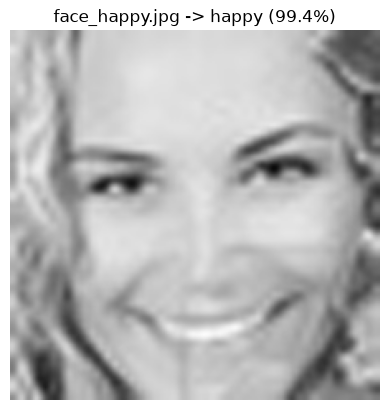

Assistant: You seem happy! How can I help you today? 



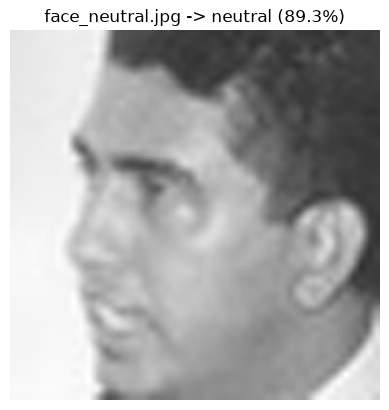

Assistant: You seem calm. Ready whenever you are. 



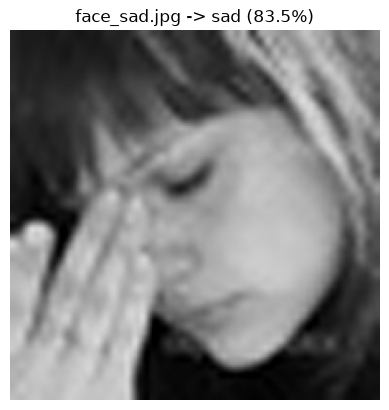

Assistant: You look a bit down. Would you like a short break or some music? 



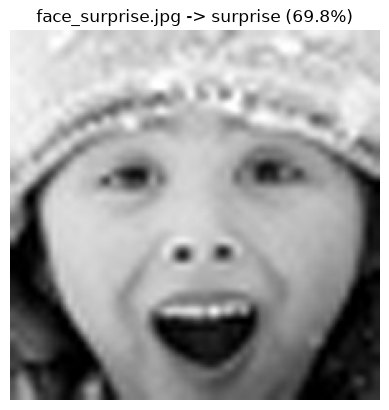

Assistant: You look surprised! Want me to explain what happened? 



,File,Emotion,Confidence %,Response
0,face_happy.jpg,happy,99.400002,You seem happy! How can I help you today?
1,face_neutral.jpg,neutral,89.300003,You seem calm. Ready whenever you are.
2,face_sad.jpg,sad,83.500000,You look a bit down. Would you like a short break or som...
3,face_surprise.jpg,surprise,69.800003,You look surprised! Want me to explain what happened?


In [5]:
from deepface import DeepFace

# Put 3-5 face photos (happy, sad, surprised, neutral) in 'face_images'
FACE_DIR = "face_images"
os.makedirs(FACE_DIR, exist_ok=True)
face_files = sorted(f for f in os.listdir(FACE_DIR) if f.lower().endswith((".jpg", ".jpeg", ".png")))
print(face_files)

responses = {
    "happy":    "You seem happy! How can I help you today?",
    "sad":      "You look a bit down. Would you like a short break or some music?",
    "angry":    "You seem frustrated. Let me simplify things step by step.",
    "fear":     "You appear worried. I will guide you carefully.",
    "surprise": "You look surprised! Want me to explain what happened?",
    "disgust":  "Something seems off. Tell me what's wrong and I'll help.",
    "neutral":  "You seem calm. Ready whenever you are.",
}

rows = []
for f in face_files:
    path = f"{FACE_DIR}/{f}"
    res = DeepFace.analyze(path, actions=["emotion"], enforce_detection=False)[0]
    emo = res["dominant_emotion"]
    conf = res["emotion"][emo]

    plt.imshow(cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB))
    plt.title(f"{f} -> {emo} ({conf:.1f}%)"); plt.axis("off"); plt.show()
    print("Assistant:", responses[emo], "\n")

    rows.append({"File": f, "Emotion": emo, "Confidence %": round(conf, 1), "Response": responses[emo]})

pd.DataFrame(rows)